# Dataset Overview

## Firmware Import Metrics

In [166]:
# Input File Configuration
DATASET_PATH = "./data/02_octopus/static_analysis/"
FMD_FIRMWARE_FILE = f"{DATASET_PATH}FirmwareDroid.android_firmware_v2.json"
FMD_BUILD_PROP_FILE = f"{DATASET_PATH}FirmwareDroid.build_props_v4.json"
ANDROID_VERSION_LIST = ["12", "12_1", "13", "14", "15", "16"]
# Map Android versions to SDK labels
VERSION_TO_SDK = {
    "12": "SDK31",
    "12_1": "SDK32",
    "13": "SDK33",
    "14": "SDK34",
    "15": "SDK35",
    "16": "SDK36"
}

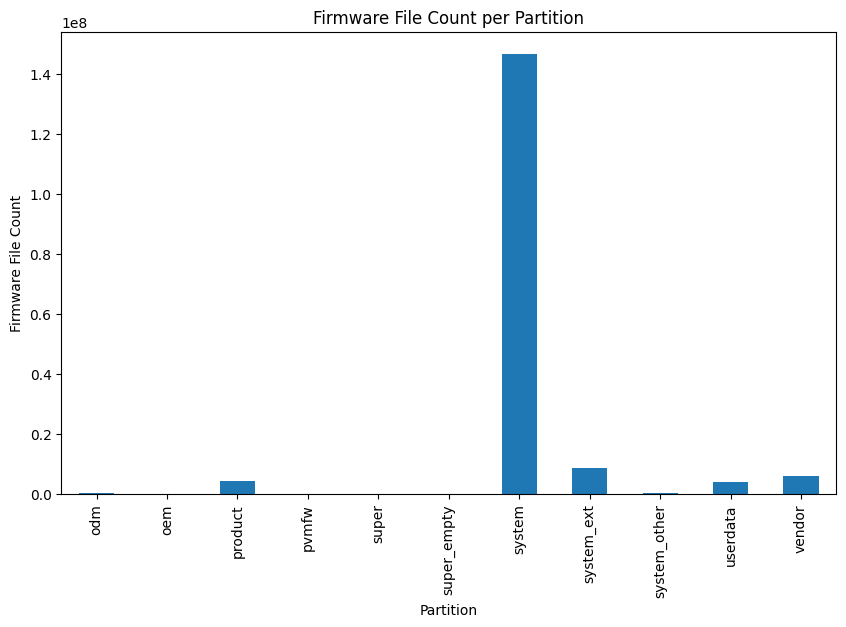

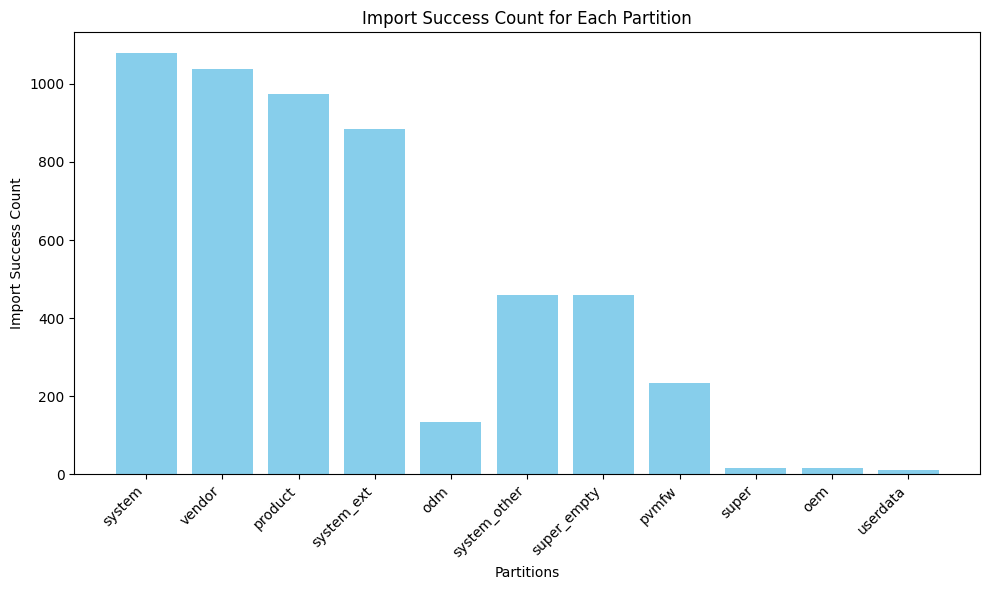

In [167]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
import numpy as np
import squarify

# Load the JSON data
with open(FMD_FIRMWARE_FILE, 'r') as file:
    data = json.load(file)

# Flatten the JSON data for easier analysis
records = []
for item in data:
    filename = item['filename']
    key = "partitionInfoDict"
    if key in item.keys():
        key = "partitionInfoDict"
    else:
        key = "partition_info_dict"


    for partition, details in item[key].items():
        records.append({
            'filename': filename,
            'partition': partition,
            'is_import_success': details['is_import_success'],
            'firmware_file_count': details['firmware_file_count'],
            'android_app_count': details['android_app_count'],
            'build_prop_count': details['build_prop_count']
        })

df = pd.DataFrame(records)
# 1. Bar Chart: Firmware file count per partition
partition_firmware_counts = df.groupby('partition')['firmware_file_count'].sum()
partition_firmware_counts.plot(kind='bar', figsize=(10, 6), title='Firmware File Count per Partition')
plt.xlabel('Partition')
plt.ylabel('Firmware File Count')
plt.show()
# Initialize a dictionary to count import success for each partition
partition_success_count = defaultdict(int)

# Process the data
for item in data:
    key = "partitionInfoDict"
    if key in item.keys():
        key = "partitionInfoDict"
    else:
        key = "partition_info_dict"
    partition_info = item.get(key, {})
    for partition, details in partition_info.items():
        if details.get("is_import_success", False):
            partition_success_count[partition] += 1

# Prepare data for the bar chart
partitions = list(partition_success_count.keys())
success_counts = list(partition_success_count.values())

# Plot the bar chart
plt.figure(figsize=(10, 6))
plt.bar(partitions, success_counts, color='skyblue')
plt.xlabel('Partitions')
plt.ylabel('Import Success Count')
plt.title('Import Success Count for Each Partition')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()




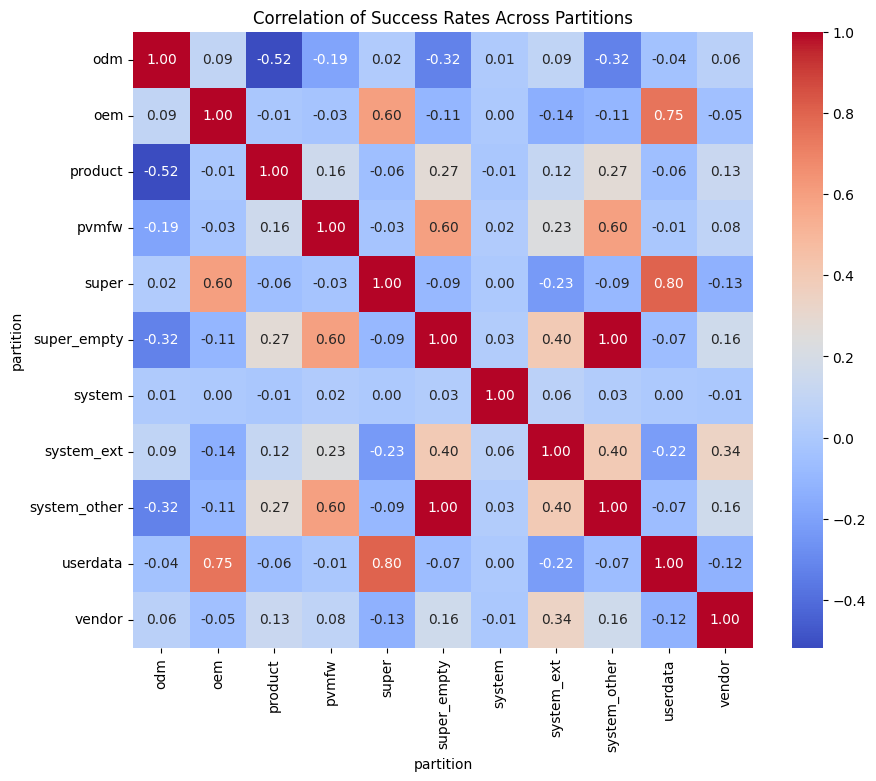

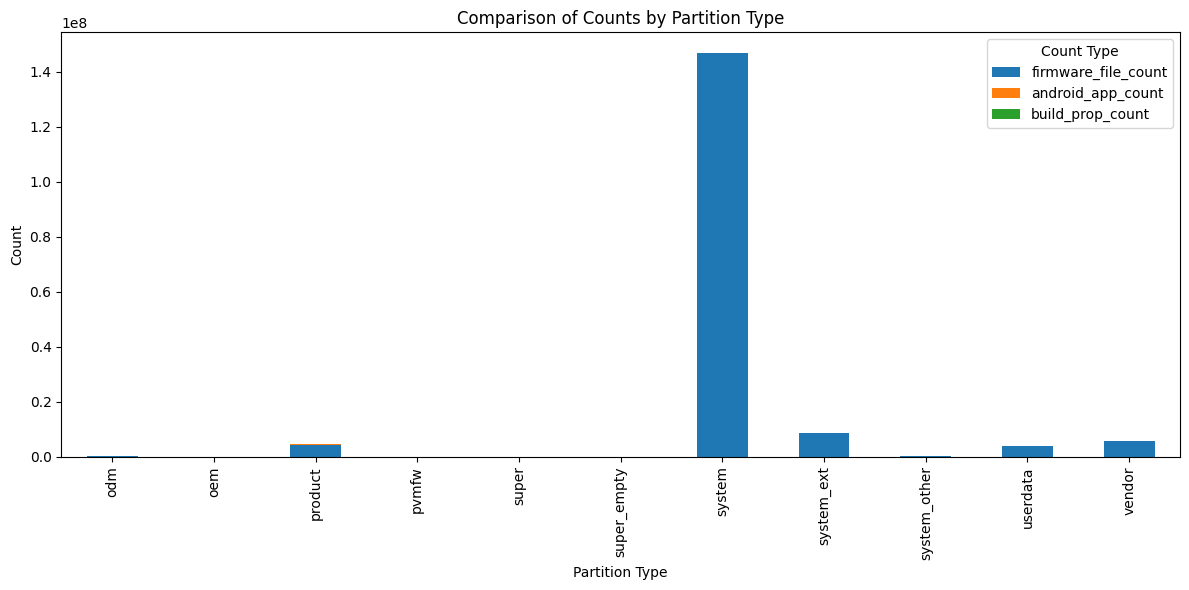

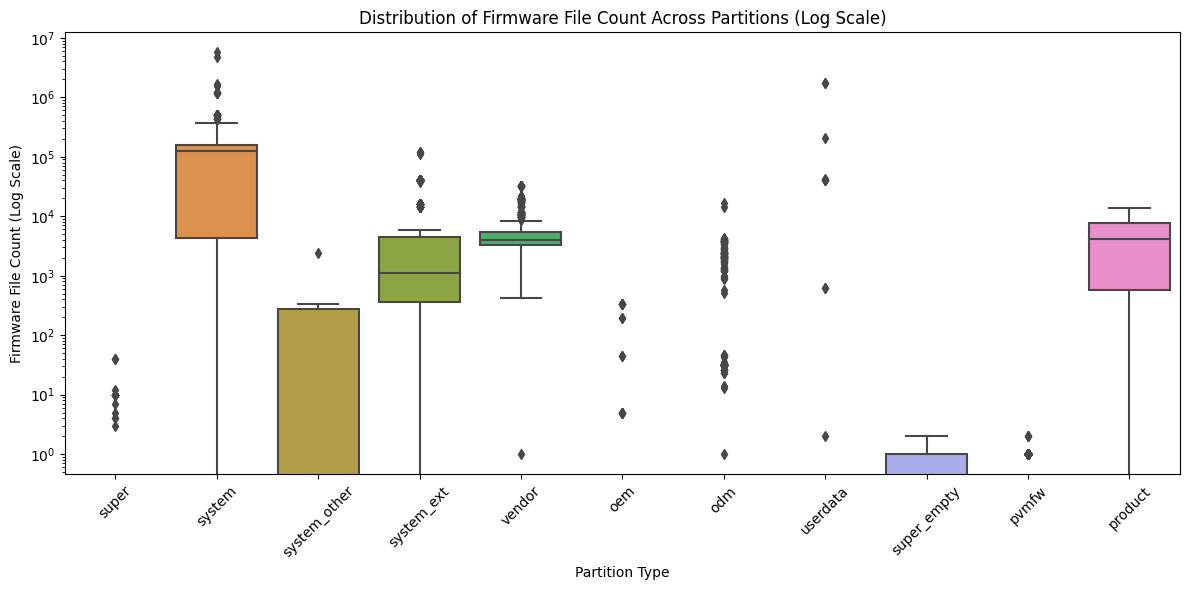

In [168]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Flatten the data into a DataFrame
records = []
for item in data:
    key = "partitionInfoDict"
    if key in item.keys():
        key = "partitionInfoDict"
    else:
        key = "partition_info_dict"
    partition_info = item[key]
    for partition, details in partition_info.items():
        records.append({
            'filename': item['filename'],
            'partition': partition,
            'is_import_success': details['is_import_success'],
            'firmware_file_count': details['firmware_file_count'],
            'android_app_count': details['android_app_count'],
            'build_prop_count': details['build_prop_count']
        })

df = pd.DataFrame(records)

# Calculate success rate per partition
success_rate = df.groupby('partition')['is_import_success'].mean().reset_index()
success_rate.columns = ['partition', 'success_rate']

# Pivot for correlation
correlation_data = df.pivot_table(index='filename', columns='partition', values='is_import_success', aggfunc='mean')

# Plot correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation of Success Rates Across Partitions')
plt.show()
# Flatten the data for easier processing
records = []
for item in data:
    key = "partitionInfoDict"
    if key in item.keys():
        key = "partitionInfoDict"
    else:
        key = "partition_info_dict"
    for partition, values in item[key].items():
        records.append({
            'filename': item['filename'],
            'partition': partition,
            'firmware_file_count': values['firmware_file_count'],
            'android_app_count': values['android_app_count'],
            'build_prop_count': values['build_prop_count']
        })

df = pd.DataFrame(records)

# Stacked Bar Chart
partition_sums = df.groupby('partition')[['firmware_file_count', 'android_app_count', 'build_prop_count']].sum()
partition_sums.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Comparison of Counts by Partition Type')
plt.ylabel('Count')
plt.xlabel('Partition Type')
plt.legend(title='Count Type')
plt.tight_layout()
plt.show()
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='partition', y='firmware_file_count')
plt.yscale('log')  # Set y-axis to log scale
plt.title('Distribution of Firmware File Count Across Partitions (Log Scale)')
plt.ylabel('Firmware File Count (Log Scale)')
plt.xlabel('Partition Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## Firmware Meta-Data Analysis

In [169]:
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd
import json
import base64
import pandas as pd
import seaborn as sns

SDK_VERSION_PROPERTIES_LIST = [
    "ro.build.version.sdk",
    "ro_build_version_sdk",
    "ro_system_build_version_sdk",
    "ro.system.build.version.sdk",
]


with open(FMD_BUILD_PROP_FILE, 'r') as file:
    data = json.load(file)
    data_dict = {"build_property_file_list": []}
    android_firmware_list = data['data']['build_prop_file_id_list']
    print(f"Total build property files count: {len(android_firmware_list)}")

    firmware_id_list = set()
    for node in android_firmware_list:
        #print(node)
        build_property_id = node["pk"]
        if "firmwareIdReference" in node.keys() and node["firmwareIdReference"] is None:
            #print(f"Firmware ID reference is null for build property ID: {build_property_id}")
            android_firmware_list.remove(node)
            continue

        firmware_id = node["firmwareIdReference"]["pk"]
        file_dict = {"build_property_id": build_property_id, "firmware_id": firmware_id, "build_properties": {}}
        build_properties = node["properties"]
        properties_dict = json.loads(build_properties)

        # Filter all build property files that do not contain any SDK version information, as these are not relevant for our analysis.
        has_sdk_version = False
        for candidate in SDK_VERSION_PROPERTIES_LIST:
            if candidate in properties_dict:
                has_sdk_version = True
                break
        if has_sdk_version and firmware_id not in firmware_id_list:
            for key, value in properties_dict.items():
                file_dict["build_properties"][key] = value
            data_dict["build_property_file_list"].append(file_dict)
            firmware_id_list.add(firmware_id)

    print(f"Total build property files with SDK version information: {len(data_dict['build_property_file_list'])}")


Total build property files count: 84341
Total build property files with SDK version information: 3632


In [170]:
from collections import defaultdict
# defaultdict makes it easier to append firmware_ids
sdk_versions_dict = defaultdict(list)

for entry in data_dict['build_property_file_list']:
    fw_id = entry["firmware_id"]
    sdk_version = entry["build_properties"].get("ro_build_version_sdk")

    if sdk_version:
        sdk_versions_dict[sdk_version].append(fw_id)

# If you want a plain dict instead of defaultdict
sdk_versions_dict = dict(sdk_versions_dict)
print(sdk_versions_dict)

{'32': ['68af0f3e65e2ad36cf732fc8', '68af0f0865e2ad36cf731949', '68afa63065e2ad36cff0e277', '68afc71965e2ad36cf0c4584', '68b00a1665e2ad36cf430442', '68b014e565e2ad36cf4b16c5', '68b0650765e2ad36cf8e8100', '68b0f76c65e2ad36cffc4271', '68b1259c65e2ad36cf1f93fb', '68b13c0765e2ad36cf3046f8', '68b1577465e2ad36cf46a434', '68b15e7865e2ad36cf4b1435', '68b1cdb665e2ad36cfa30dbb', '68b1d3db65e2ad36cfa89938', '68b1e78065e2ad36cfb8a415', '68b1f27165e2ad36cfc1979b', '68b200c865e2ad36cfcc7b51', '68b214e665e2ad36cfdd617a', '68b2234d65e2ad36cfe68aa8', '68b231bb65e2ad36cff19010', '68b240b465e2ad36cfff9375', '68b25dc465e2ad36cf15ce8d', '68b2bc4c65e2ad36cf594a18', '68b2c8b265e2ad36cf61f56b', '68b2e79465e2ad36cf7b303e', '68b308e265e2ad36cf948f21', '698333e770168e916d923207', '69833a3970168e916d998afb', '69833b8f70168e916d9a7611', '69834bad70168e916da8547e', '6984814eab2ebd4d0609bdf6', '6984893aab2ebd4d06102a2b', '69848d9fab2ebd4d06144edb', '698491e1ab2ebd4d0617ab93', '69849395ab2ebd4d0618b08a', '69849a10ab2

In [171]:
allowed_sdks = {"31", "32", "33", "34", "35", "36"}

# Split into kept and removed entries
kept_entries = []
removed_entries = []

for e in data_dict['build_property_file_list']:
    if e["build_properties"].get("ro_build_version_sdk") in allowed_sdks:
        kept_entries.append(e)
    else:
        removed_entries.append(e)

print(f"Number of entries removed: {len(removed_entries)}")
print("Removed entries due to wrong SDK version:")
for e in removed_entries:
    print(e["firmware_id"])

print(f"\nNumber of entries remaining: {len(kept_entries)}")
print("Remaining entries:")
list_31 = set()
list_32 = set()
list_33 = set()
list_34 = set()
list_35 = set()
list_36 = set()


Number of entries removed: 2515
Removed entries due to wrong SDK version:
68b2e0d965e2ad36cf7404db
68d67b3ff77094f209a08904
697a213e115eefe61b17fe2f
697a24a1115eefe61b1bc9bd
697a2664115eefe61b1d3f40
697a2a77115eefe61b216a46
697a2dad115eefe61b248e13
697a2dab115eefe61b248c24
697a2f74115eefe61b268765
697a2f8d115eefe61b26a31b
697a3179115eefe61b291089
697a329a115eefe61b2a679e
697a3316115eefe61b2afc61
697aa54370168e916de55c30
697aa4e470168e916de5305c
697aacdd70168e916dea50ef
697acd0570168e916d0c7866
697ad4a570168e916d14c464
697ad8f970168e916d19a942
697ad84670168e916d18e33e
697adb3670168e916d1bcdf5
697aebec70168e916d2f72f4
697af11670168e916d34ceff
697af37570168e916d37d8f4
697af85c70168e916d3e1755
697afa8470168e916d410e66
697afd9d70168e916d43aeba
697b102270168e916d560325
697b118670168e916d57759b
697b143b70168e916d5a41e3
697b16eb70168e916d5d2963
697b628870168e916da9708d
697b78e270168e916dab4a0a
697b7a3f70168e916dab6ece
697b911970168e916dadeca2
697b95f670168e916daf7060
697b97a870168e916daff4a0
6

In [172]:
for e in kept_entries:
    #print(e["firmware_id"])
    if e["build_properties"].get("ro_build_version_sdk") == "31":
        list_31.add(e["firmware_id"])
    elif e["build_properties"].get("ro_build_version_sdk") == "32":
        list_32.add(e["firmware_id"])
    elif e["build_properties"].get("ro_build_version_sdk") == "33":
        list_33.add(e["firmware_id"])
    elif e["build_properties"].get("ro_build_version_sdk") == "34":
        list_34.add(e["firmware_id"])
    elif e["build_properties"].get("ro_build_version_sdk") == "35":
        list_35.add(e["firmware_id"])
    elif e["build_properties"].get("ro_build_version_sdk") == "36":
        list_36.add(e["firmware_id"])

print(f"Len 31: {len(list_31)}")
print(f"Len 32: {len(list_32)}")
print(f"Len 33: {len(list_33)}")
print(f"Len 34: {len(list_34)}")
print(f"Len 35: {len(list_35)}")
print(f"Len 36: {len(list_36)}")
print(f"Total: {len(list_31) + len(list_32) + len(list_33) + len(list_34) + len(list_35) + len(list_36)}")





Len 31: 302
Len 32: 76
Len 33: 451
Len 34: 174
Len 35: 99
Len 36: 15
Total: 1117


In [173]:
print(f"SDK 31: {list_31}")
print(f"SDK 32: {list_32}")
print(f"SDK 33: {list_33}")
print(f"SDK 34: {list_34}")
print(f"SDK 35: {list_35}")
print(f"SDK 36: {list_36}")


SDK 31: {'68af110965e2ad36cf7475cd', '68b1579065e2ad36cf46a90a', '68b2ff7a65e2ad36cf8d5b72', '68b21be565e2ad36cfe0cf20', '697d3d2a70168e916db20237', '699842380712f939de0c236d', '6998d0760712f939de41b240', '6999da040712f939dea8c55a', '699bb5bf0712f939de2a3acf', '68b230f765e2ad36cff14e06', '699737890712f939deb90466', '6985c536ab2ebd4d06053e02', '6998f4370712f939de4ffab2', '69901f54e0e6709b7b6e9070', '6998af200712f939de3375a4', '68b1c52865e2ad36cf9fb03c', '697fc7e170168e916d3f7cb2', '699898720712f939de272574', '68b10b9365e2ad36cf09d98f', '68b26d9c65e2ad36cf21d030', '699afa730712f939deef1556', '698c1b2cab2ebd4d06d32e2d', '6999ccbc0712f939dea1f3c3', '68af42df65e2ad36cf9fe2e2', '699ba3830712f939de216416', '68b1515465e2ad36cf416220', '68b2a87f65e2ad36cf4bc02d', '698957f9ab2ebd4d061dc4b3', '699bafc90712f939de26ee45', '698957afab2ebd4d061db9e5', '6985c6fbab2ebd4d0605f9cf', '68b280f165e2ad36cf2f0786', '68af169465e2ad36cf7871b7', '697a2621115eefe61b1d0572', '6999bbfa0712f939de99a74f', '6998b29807

In [174]:
print(kept_entries[0])
print(len(kept_entries))
data_dict = kept_entries

{'build_property_id': '68af0d9865e2ad36cf718126', 'firmware_id': '68af0f3e65e2ad36cf732fc8', 'build_properties': {'ro_product_system_brand': 'google', 'ro_product_system_device': 'generic', 'ro_product_system_manufacturer': 'Google', 'ro_product_system_model': 'mainline', 'ro_product_system_name': 'mainline', 'ro_system_product_cpu_abilist': 'arm64-v8a,armeabi-v7a,armeabi', 'ro_system_product_cpu_abilist32': 'armeabi-v7a,armeabi', 'ro_system_product_cpu_abilist64': 'arm64-v8a', 'ro_system_build_date': 'Wed Jun  1 23:25:36 UTC 2022', 'ro_system_build_date_utc': '1654125936', 'ro_system_build_fingerprint': 'google/oriole/oriole:12/SQ3A.220705.003.A1/8672226:user/release-keys', 'ro_system_build_id': 'SQ3A.220705.003.A1', 'ro_system_build_tags': 'release-keys', 'ro_system_build_type': 'user', 'ro_system_build_version_incremental': '8672226', 'ro_system_build_version_release': '12', 'ro_system_build_version_release_or_codename': '12', 'ro_system_build_version_sdk': '32', 'ro_build_id': 'SQ3

# Build Property Key Analysis

In [175]:
# Set plot stylingfor a clean scientific look suitable for publication
import matplotlib as mpl
import matplotlib.pyplot as plt

def set_scientific_style():
    mpl.rcParams.update({
        # Font
        "font.family": "serif",
        "font.size": 11,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,

        # Lines
        "axes.linewidth": 0.8,
        "lines.linewidth": 1.2,

        # Grid
        "axes.grid": True,
        "grid.linestyle": "--",
        "grid.linewidth": 0.5,
        "grid.alpha": 0.4,

        # Remove top/right spines
        "axes.spines.top": False,
        "axes.spines.right": False,

        # Figure DPI (important for PDF export)
        "figure.dpi": 300,
        "savefig.dpi": 300,

        # PDF font embedding
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    plt.style.use("default")

set_scientific_style()

In [176]:
def get_all_keys():
    all_keys = set()
    for firmware_entry in data_dict:
        for key in firmware_entry['build_properties'].keys():
            all_keys.add(key)
    return list(all_keys)

def get_frequencies(target_key):
    frequency_dict = {}

    for firmware_entry in data_dict:
        current_firmware_id = firmware_entry['firmware_id']
        if current_firmware_id not in firmware_id_list:
            print(f"Firmware ID {current_firmware_id} not in the allowed firmware ID list, skipping entry.")
            continue

        if target_key not in frequency_dict:
            frequency_dict[target_key] = []

        if target_key in firmware_entry['build_properties']:
            value = firmware_entry['build_properties'][target_key]
            value = value.capitalize()
            frequency_dict[target_key].append(value)
        else:
            # Handle specific cases for missing keys of brand naming of the system key. Adding the vendor brand if available.
            if target_key == "ro_product_system_brand" and "ro_product_vendor_brand" in firmware_entry['build_properties']:
                value = firmware_entry['build_properties']["ro_product_vendor_brand"]
                value = value.capitalize()
                if "ro_product_vendor_brand" not in frequency_dict:
                    frequency_dict["ro_product_vendor_brand"] = []
                frequency_dict["ro_product_vendor_brand"].append(value)
            elif target_key == "ro_product_system_brand" and "ro_product_odm_manufacturer" in firmware_entry['build_properties']:
                value = firmware_entry['build_properties']["ro_product_odm_manufacturer"]
                value = value.capitalize()
                if "ro_product_odm_manufacturer" not in frequency_dict:
                    frequency_dict["ro_product_odm_manufacturer"] = []
                frequency_dict["ro_product_odm_manufacturer"].append(value)
            else:
                if target_key == "ro_product_system_brand":
                    print(f"Key '{target_key}' not found in firmware entry: {firmware_entry['firmware_id']}")
                frequency_dict[target_key].append("N/A")

    return frequency_dict

def get_all_frequencies():
    frequency_dict = {}
    all_keys = get_all_keys()
    for key in all_keys:
        frequency_dict[key] = get_frequencies(key)[key]
    return frequency_dict

def plot_frequency(value_list, title=None, output_file=None, x_title="Values", y_title="Frequency"):
    property_counts = Counter(value_list)

    # Use seaborn to set the style and color palette
    #sns.set_style('whitegrid')
    #sns.set_palette('colorblind')  # Use a colorblind-friendly palette
    fig, ax = plt.subplots(figsize=(8, 6))  # Adjust figure size for better readability

    # Plot the frequency
    bars = ax.bar(property_counts.keys(), property_counts.values(), color=sns.color_palette('colorblind'), edgecolor='black')
    ax.set_xlabel(x_title, fontsize=14)
    ax.set_ylabel(y_title, fontsize=14)
    ax.tick_params(axis='y', labelsize=10)
    ax.tick_params(axis='x', labelsize=10, rotation=90)
    if title:
        ax.set_title(title, fontsize=16, weight='bold')
    plt.xticks(rotation=90, ha='right')
    plt.tight_layout()

    # Add numbers on top of the bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, height, f'{height}', ha='center', va='bottom', fontsize=10)

    # Save the plot as a PDF if output_file is provided
    if output_file:
        plt.savefig(output_file, format='pdf', bbox_inches='tight', dpi=300)  # High resolution for publication

    plt.show()

def plot_frequency_horizontal(value_list, title=None, output_file=None,
                              x_title="Frequency", y_title="Values",
                              top_n=None):
    counts = Counter(value_list)

    if top_n:
        most_common = counts.most_common(top_n)
        labels, values = zip(*most_common)
    else:
        labels, values = zip(*counts.most_common())

    #sns.set_style('whitegrid')
    #sns.set_palette('colorblind')

    fig, ax = plt.subplots(figsize=(8, 0.4 * len(labels)))

    bars = ax.barh(labels, values, edgecolor='black')

    ax.set_xlabel(x_title, fontsize=14)
    ax.set_ylabel(y_title, fontsize=14)
    ax.tick_params(axis='y', labelsize=10)
    ax.tick_params(axis='x', labelsize=10, rotation=90)

    if title:
        ax.set_title(title, fontsize=16, weight='bold')

    ax.invert_yaxis()  # Highest frequency on top

    for bar in bars:
        width = bar.get_width()
        ax.text(width, bar.get_y() + bar.get_height()/2,
                f'{width}', va='center', fontsize=9)

    plt.tight_layout()

    if output_file:
        plt.savefig(output_file, format='pdf', bbox_inches='tight', dpi=300)

    plt.show()

def plot_frequency_dotplot(value_list, title=None, output_file=None,
                           x_title="Frequency", y_title="Values"):
    counts = Counter(value_list)
    labels, values = zip(*counts.most_common())

    #sns.set_style('whitegrid')
    #sns.set_palette('colorblind')

    fig, ax = plt.subplots(figsize=(8, 0.4 * len(labels)))

    ax.scatter(values, labels)

    ax.set_xlabel(x_title, fontsize=14)
    ax.set_ylabel(y_title, fontsize=14)
    ax.tick_params(axis='both', labelsize=10)

    if title:
        ax.set_title(title, fontsize=16, weight='bold')

    ax.invert_yaxis()

    for i, v in enumerate(values):
        ax.text(v, i, f' {v}', va='center', fontsize=9)

    plt.tight_layout()

    if output_file:
        plt.savefig(output_file, format='pdf', bbox_inches='tight', dpi=300)

    plt.show()



def plot_frequency_pareto(value_list, title=None, output_file=None,
                          x_title="Values", y_title="Frequency"):
    counts = Counter(value_list)
    labels, values = zip(*counts.most_common())

    values = np.array(values)
    cumulative = np.cumsum(values) / np.sum(values) * 100

    #sns.set_style('whitegrid')
    #ns.set_palette('colorblind')

    fig, ax1 = plt.subplots(figsize=(10, 6))

    bars = ax1.bar(labels, values, edgecolor='black')
    ax1.set_ylabel(y_title, fontsize=14)
    ax1.set_xlabel(x_title, fontsize=14)
    ax1.tick_params(axis='x', rotation=45)

    ax2 = ax1.twinx()
    ax2.plot(labels, cumulative, color='red', marker='o')
    ax2.set_ylabel("Cumulative Percentage (%)", fontsize=14)
    ax2.set_ylim(0, 100)

    if title:
        ax1.set_title(title, fontsize=16, weight='bold')

    plt.tight_layout()

    if output_file:
        plt.savefig(output_file, format='pdf', bbox_inches='tight', dpi=300)

    plt.show()



def plot_frequency_treemap(value_list, title=None, output_file=None):
    counts = Counter(value_list)
    labels, values = zip(*counts.most_common())

    #sns.set_style('whitegrid')
    #sns.set_palette('colorblind')

    fig = plt.figure(figsize=(10, 6))

    squarify.plot(sizes=values,
                  label=labels,
                  alpha=0.8)

    plt.axis('off')

    if title:
        plt.title(title, fontsize=16, weight='bold')

    plt.tight_layout()

    if output_file:
        plt.savefig(output_file, format='pdf', bbox_inches='tight', dpi=300)

    plt.show()

frequency_dict = get_all_frequencies()

Key 'ro_product_system_brand' not found in firmware entry: 698b8d3bab2ebd4d06792ea4
Key 'ro_product_system_brand' not found in firmware entry: 6992aff6ef248b310a236d4c


In [177]:
print(frequency_dict.keys())

dict_keys(['ro_build_kernel_id', '# qemu_hw_mainkeys', 'persist_sys_rambtnswitch', 'ro_odm_stream_alarm', 'ro_thub_core_support', 'ro_vivo_chg_shut_vbat', 'persist_oculus_timewarpRenderTime', 'persist_sys_zui_appdiagnostics', 'ro_odm_splitscreen_hide', 'ro_build_hardware_version', 'persist_service_crashlog_enable', 'ro_boot_usb_port_flag', 'ro_pt_BT_name', 'bluetooth_gd_stop_timeout', 'ro_odm_msenor_orientation_type', 'persist_vivo_support_close_gp', 'ro_product_model_apac_l', 'ro_emmc_size', 'bluetooth_powertelemetry_enabled', 'ro_vendor_tran_monkey_test', 'ro_yft_support_dg_fota', 'config_disable_permissioncontroller', 'persist_ly_audio_afe_loopback', 'ro_odm_global_device_name', 'persist_sysui_notification_ongoing_dismissal', 'ro_config_zuisdk_enabled', 'bluetooth_hfp_hf_services_mask_config', 'ro_odm_charging_sound', 'persist_vendor_audio_button_jack_switch', 'ro_vivo_product_series', 'ro_supportmodel_mptcp', 'ro_build_version_sem', 'debug_enable_sglscale', 'persist_vendor_sensors_

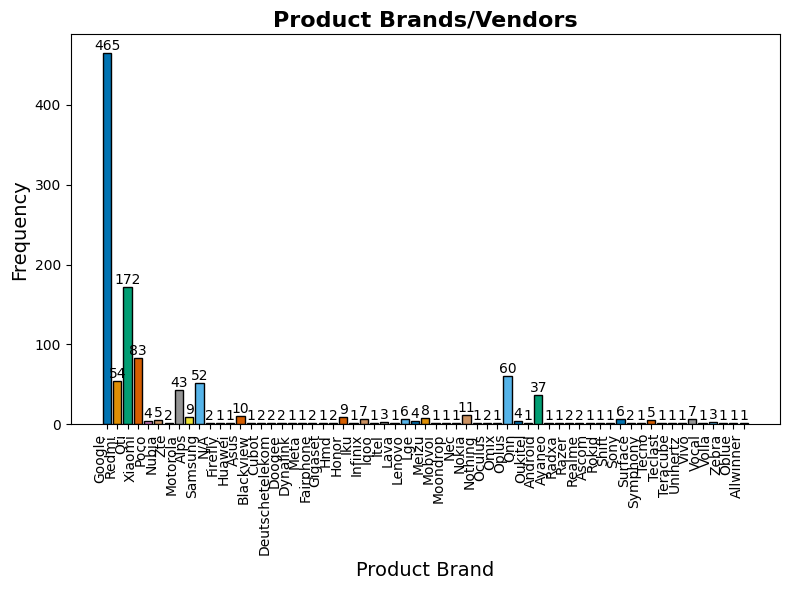

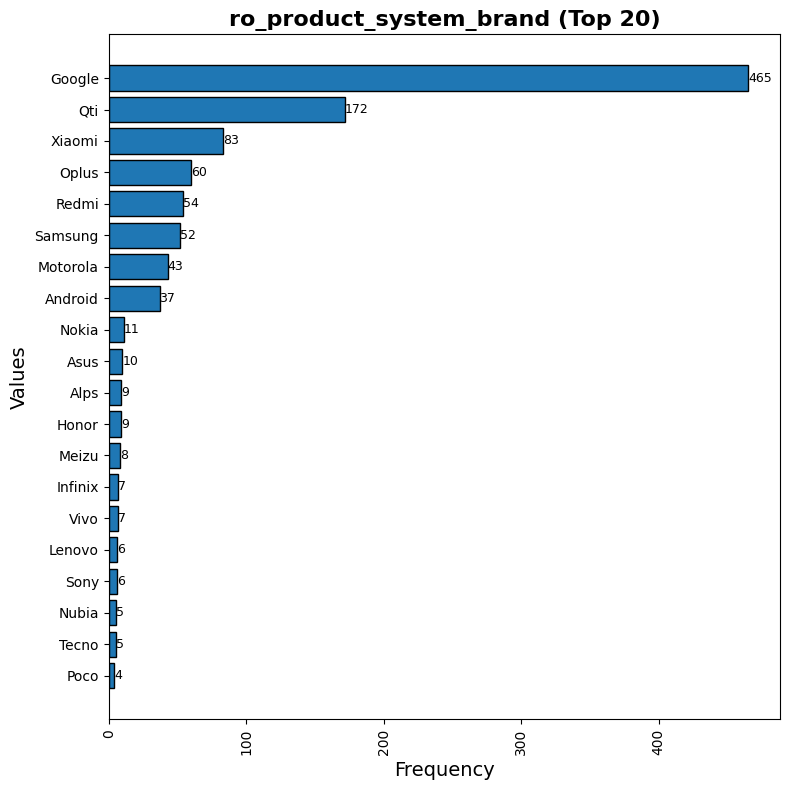

In [178]:
plot_frequency(frequency_dict["ro_product_system_brand"], title="Product Brands/Vendors", x_title="Product Brand", output_file="./images/Dataset_brand_manufacturer_mixed.pdf")
plot_frequency_horizontal(
    frequency_dict["ro_product_system_brand"],
    title="ro_product_system_brand (Top 20)",
    top_n=20,
    output_file="./images/Dataset_brand_manufacturer_mixed_horizontal.pdf"
)

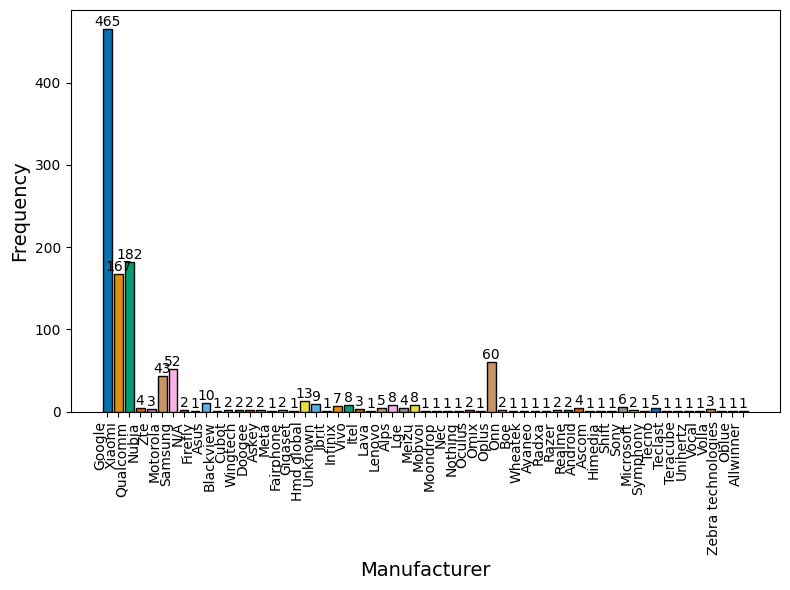

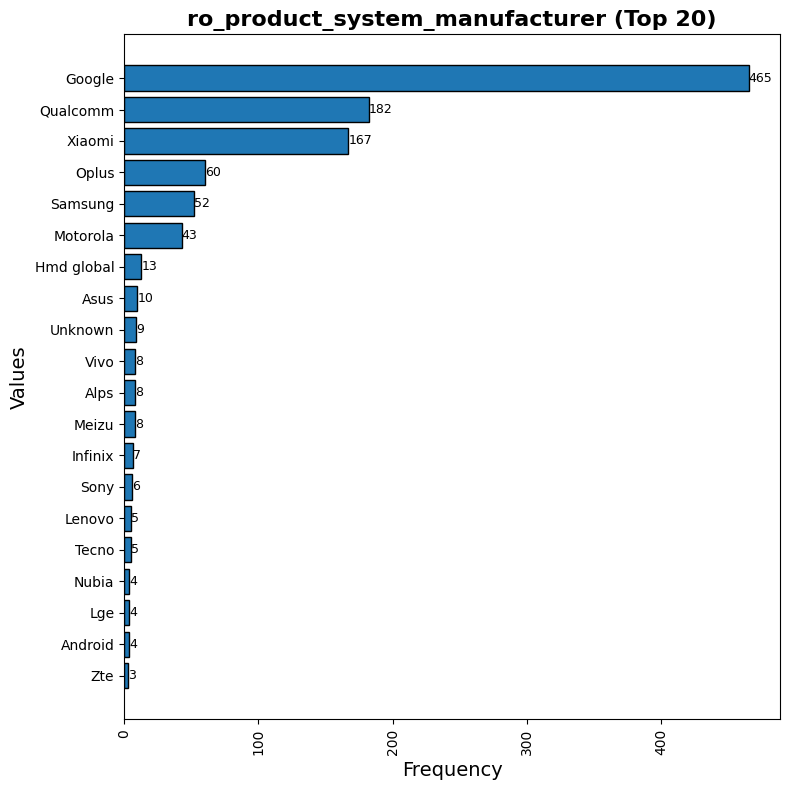

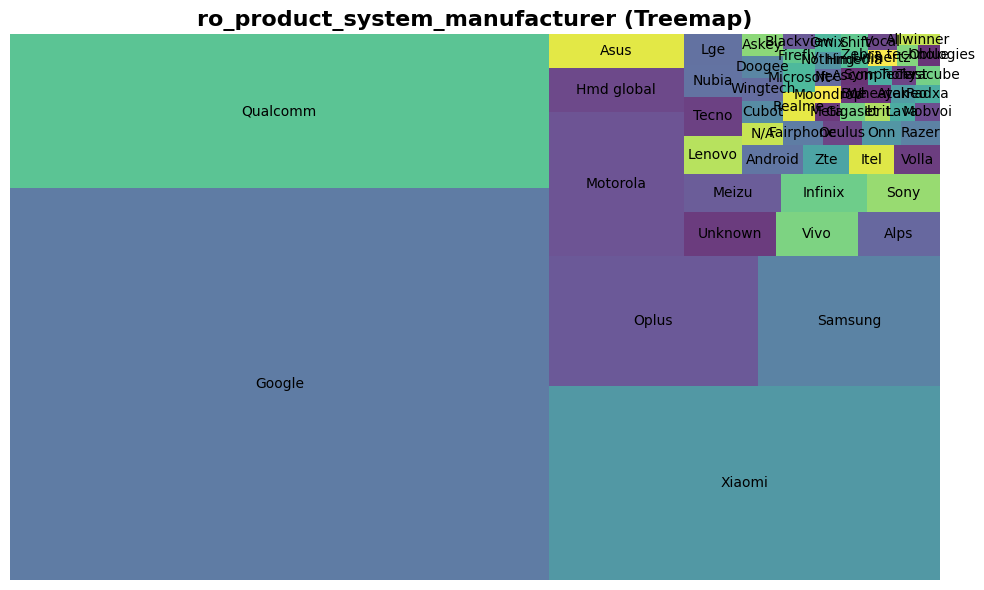

In [179]:
plot_frequency(frequency_dict["ro_product_system_manufacturer"], title=None, x_title="Manufacturer", output_file="./images/Dataset_ro_product_system_manufacturer.pdf")
plot_frequency_horizontal(
    frequency_dict["ro_product_system_manufacturer"],
    title="ro_product_system_manufacturer (Top 20)",
    top_n=20
)
plot_frequency_treemap(
    frequency_dict["ro_product_system_manufacturer"],
    title="ro_product_system_manufacturer (Treemap)"
)

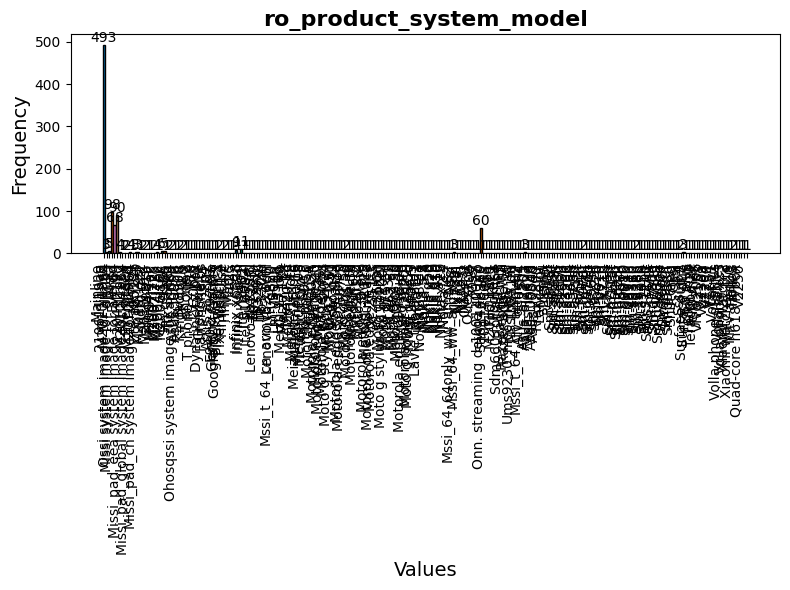

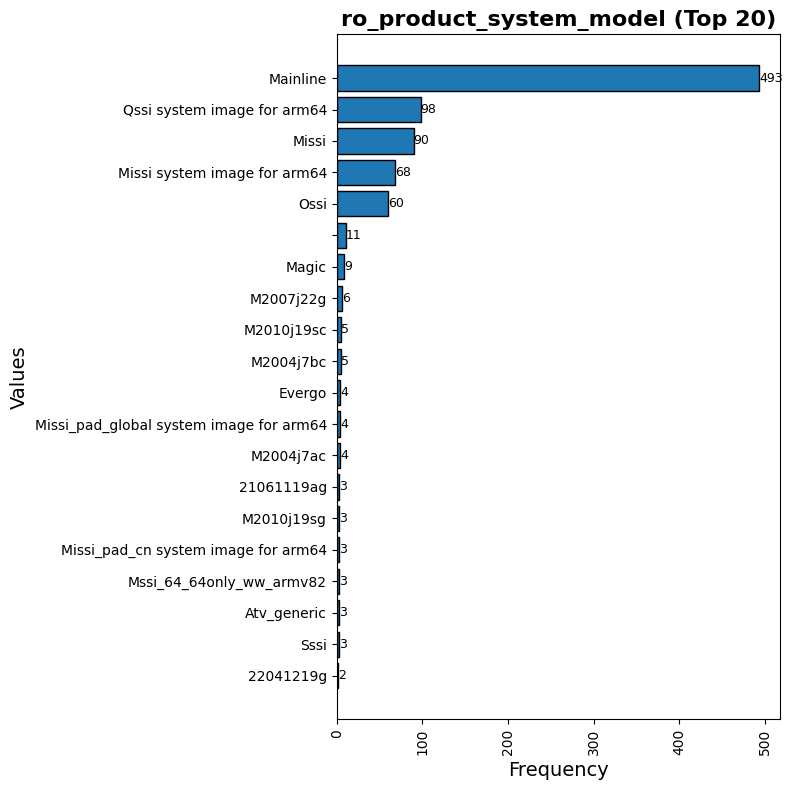

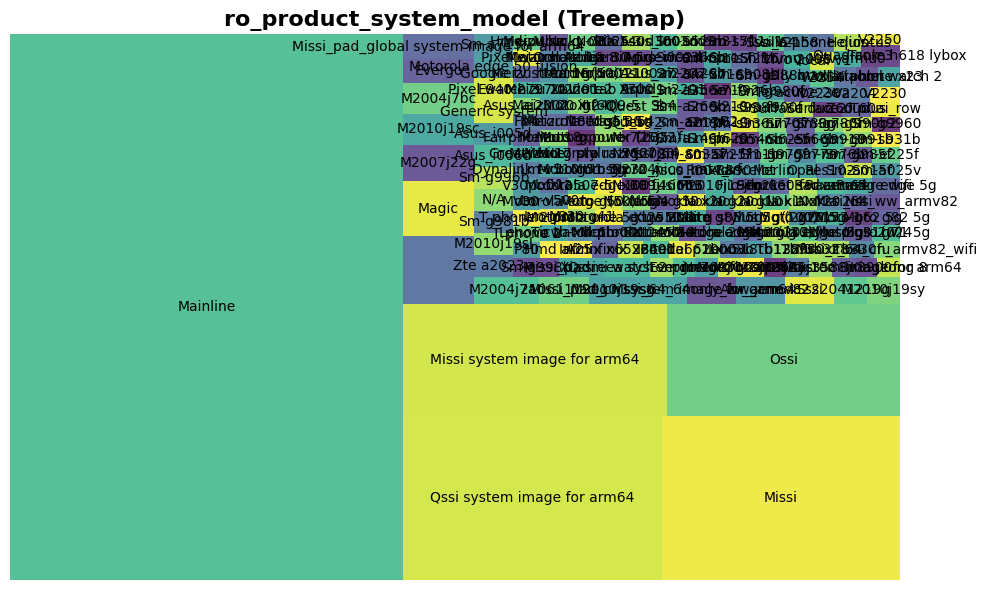

In [180]:
plot_frequency(frequency_dict["ro_product_system_model"], title="ro_product_system_model")
plot_frequency_horizontal(
    frequency_dict["ro_product_system_model"],
    title="ro_product_system_model (Top 20)",
    top_n=20
)
plot_frequency_treemap(
    frequency_dict["ro_product_system_model"],
    title="ro_product_system_model (Treemap)"
)

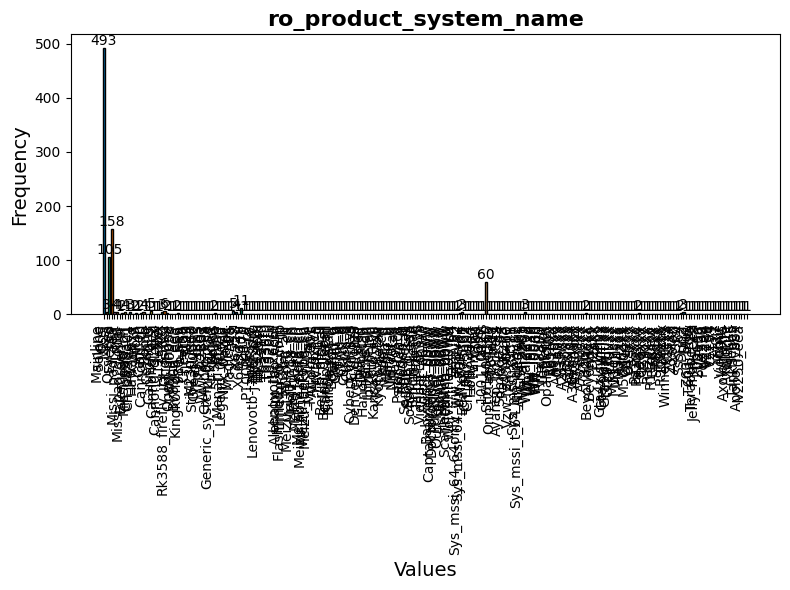

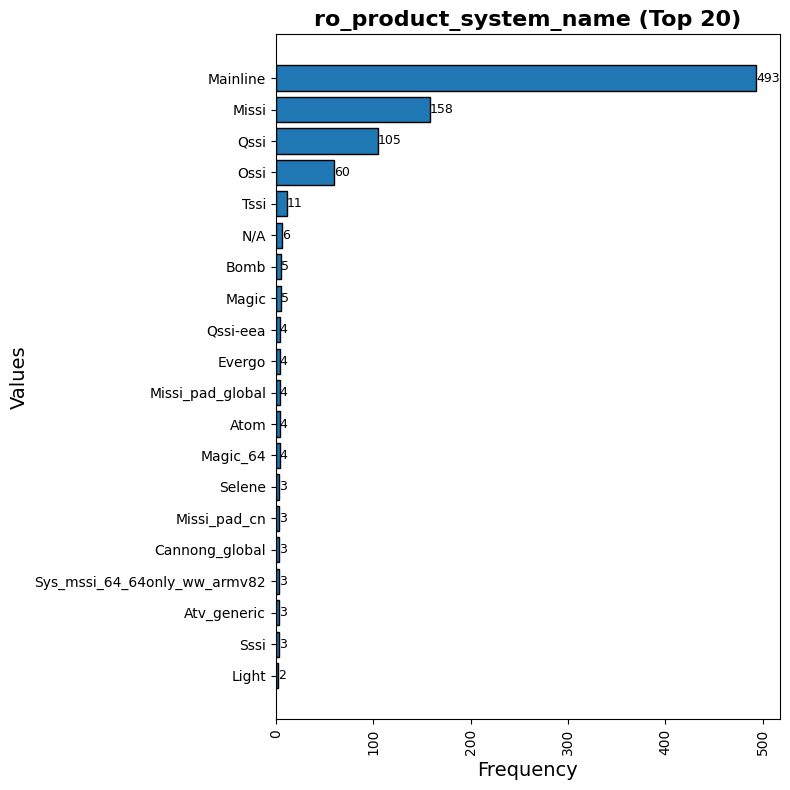

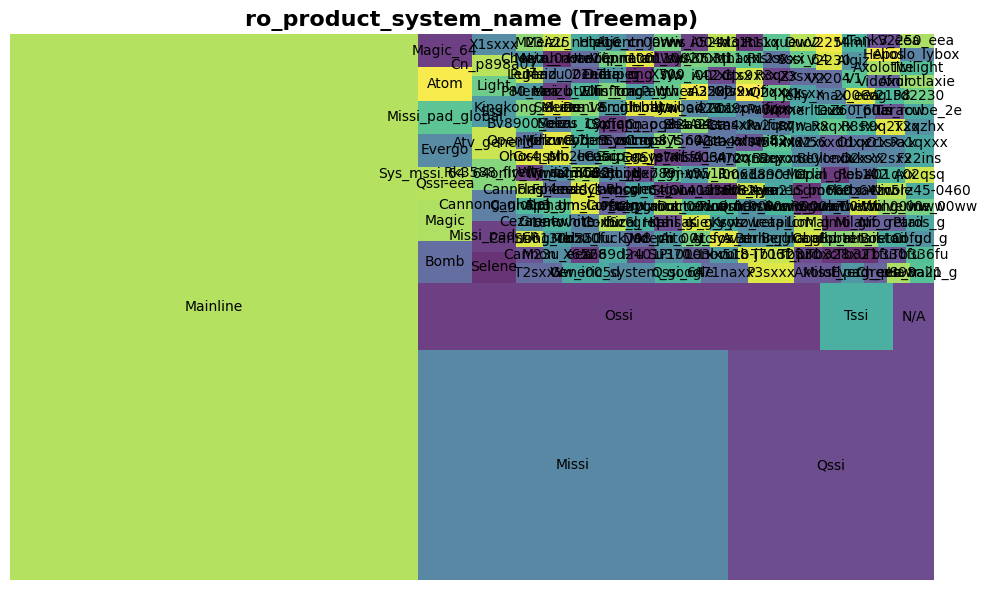

In [181]:
plot_frequency(frequency_dict["ro_product_system_name"], title="ro_product_system_name")
plot_frequency_horizontal(
    frequency_dict["ro_product_system_name"],
    title="ro_product_system_name (Top 20)",
    top_n=20
)
plot_frequency_treemap(
    frequency_dict["ro_product_system_name"],
    title="ro_product_system_name (Treemap)"
)

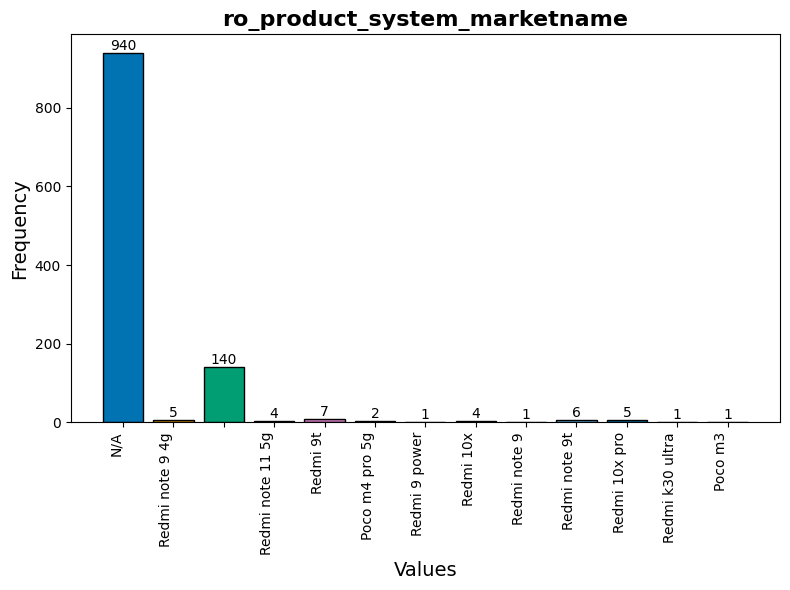

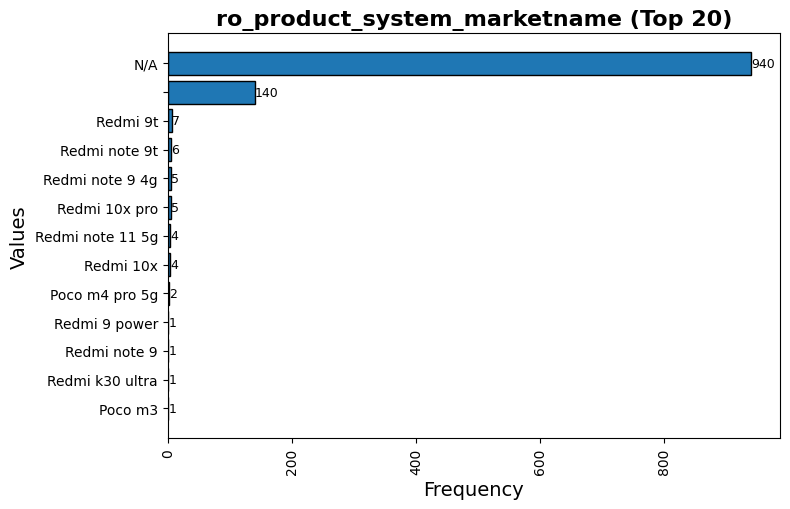

In [182]:
try:
    plot_frequency(frequency_dict["ro_product_system_marketname"], title="ro_product_system_marketname")
    plot_frequency_horizontal(
        frequency_dict["ro_product_system_marketname"],
        title="ro_product_system_marketname (Top 20)",
        top_n=20
    )
except Exception as e:
    print(e)

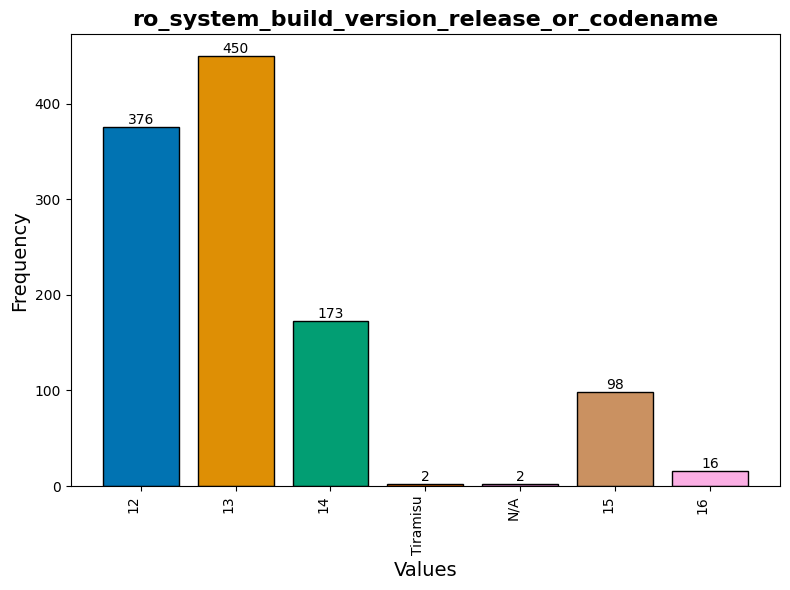

In [183]:
plot_frequency(frequency_dict["ro_system_build_version_release_or_codename"], title="ro_system_build_version_release_or_codename")

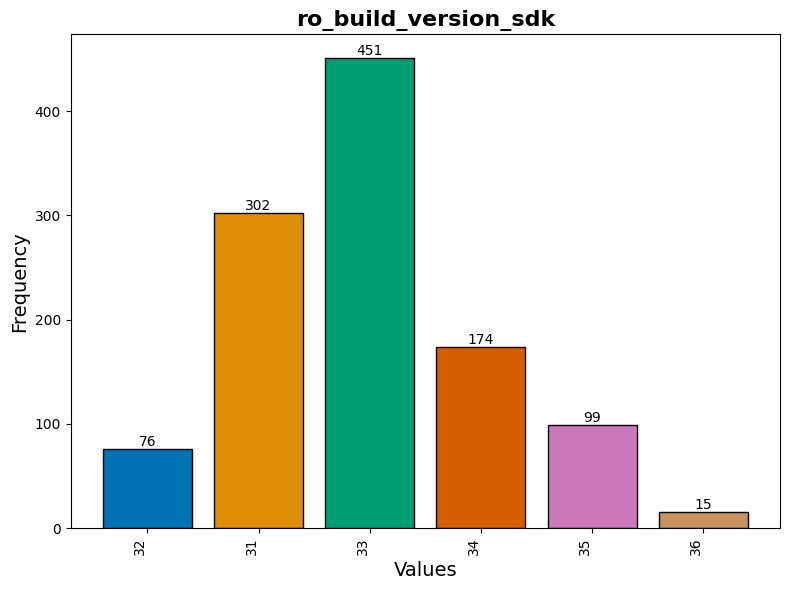

In [184]:
plot_frequency(frequency_dict["ro_build_version_sdk"], title="ro_build_version_sdk")

In [185]:
try:
    plot_frequency(frequency_dict["ro_vndk_version"], title="ro_vndk_version")
except Exception as e:
    print(e)

'ro_vndk_version'


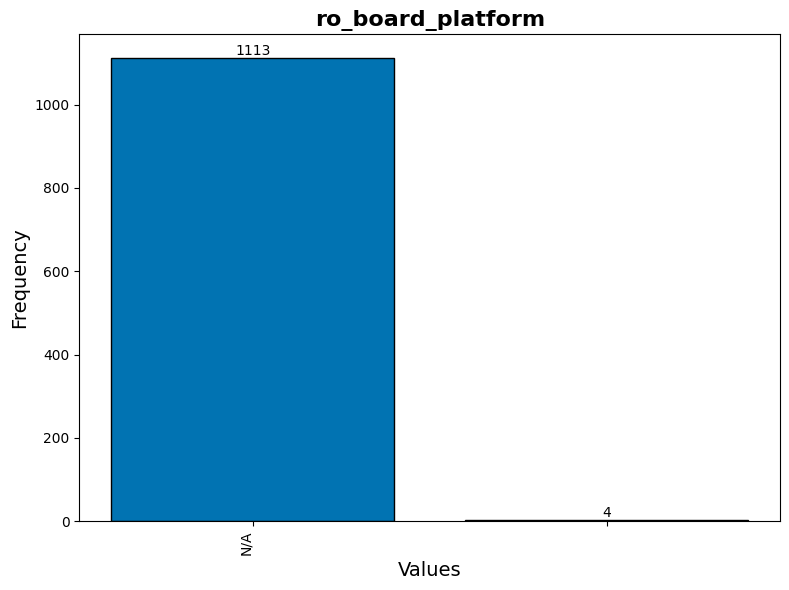

In [186]:
try:
    plot_frequency(frequency_dict["ro_board_platform"], title="ro_board_platform")
except Exception as e:
    print(e)

In [187]:
try:
    plot_frequency(frequency_dict["ro_board_api_level"], title="ro_board_api_level")
except Exception as e:
    print(e)

'ro_board_api_level'


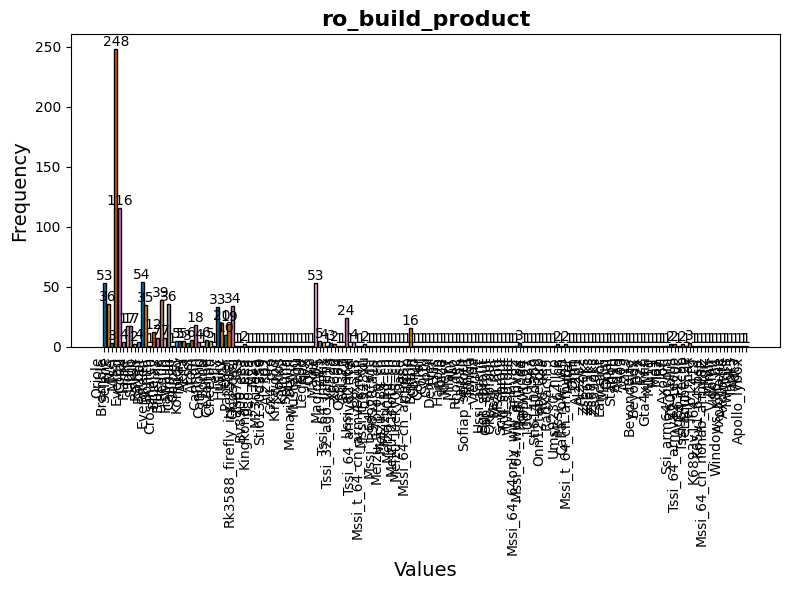

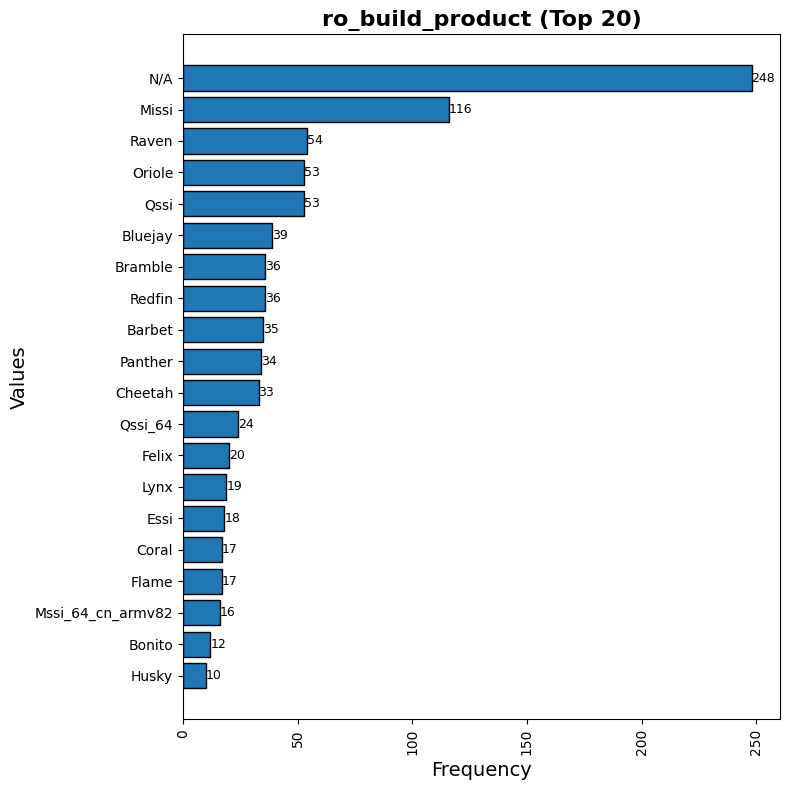

In [188]:
try:
    plot_frequency(frequency_dict["ro_build_product"], title="ro_build_product")
    plot_frequency_horizontal(
        frequency_dict["ro_build_product"],
        title="ro_build_product (Top 20)",
        top_n=20
    )
except Exception as e:
    print(e)

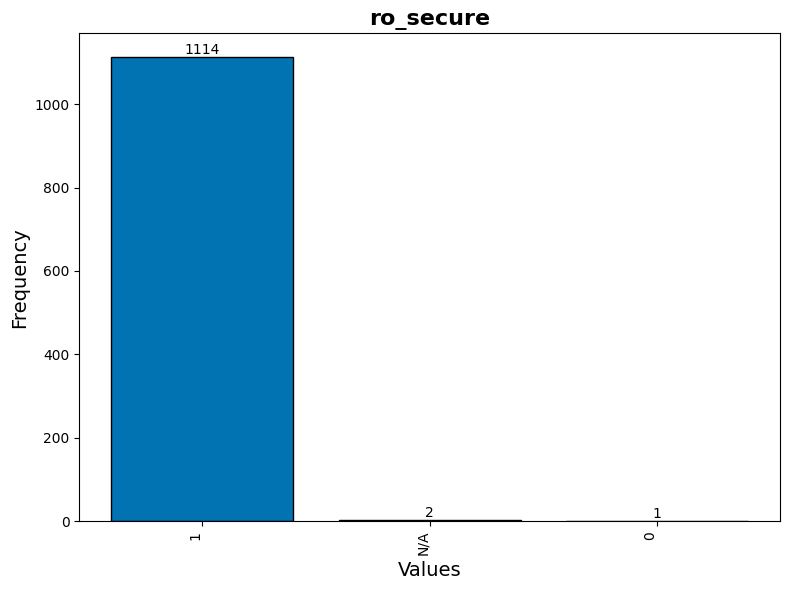

In [189]:
try:
    plot_frequency(frequency_dict["ro_secure"], title="ro_secure")
except Exception as e:
    print(e)

In [190]:
try:
    plot_frequency(frequency_dict["ro_zygote"], title="ro_zygote")
except Exception as e:
    print(e)

'ro_zygote'


In [191]:
try:
    plot_frequency(frequency_dict["ro_product_build_tags"], title="ro_product_build_tags")
except Exception as e:
    print(e)

'ro_product_build_tags'


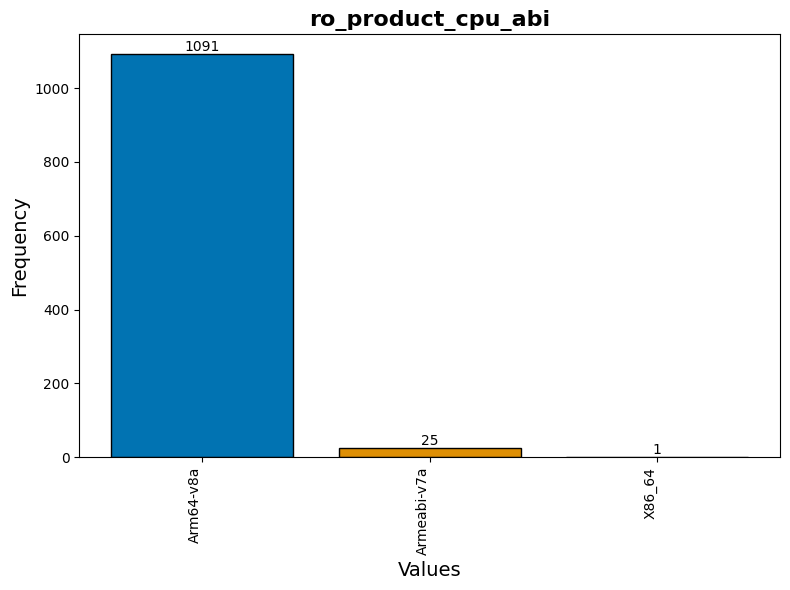

In [192]:
try:
    plot_frequency(frequency_dict["ro_product_cpu_abi"], title="ro_product_cpu_abi")
except Exception as e:
    print(e)

In [193]:
import pandas as pd

def get_grouped_brand_by_sdk(data_dict, firmware_id_list):
    records = []

    for firmware_entry in data_dict:
        current_firmware_id = firmware_entry.get('firmware_id')
        # Filter based on your allowed firmware list just like your original function
        if current_firmware_id not in firmware_id_list:
            continue

        build_props = firmware_entry.get('build_properties', {})
        sdk_version = build_props.get('ro_build_version_sdk', 'Unknown')

        # Apply your custom fallback logic for system brand
        brand = build_props.get('ro_product_system_brand')
        if not brand:
            if "ro_product_vendor_brand" in build_props:
                brand = build_props["ro_product_vendor_brand"]
            elif "ro_product_odm_manufacturer" in build_props:
                brand = build_props["ro_product_odm_manufacturer"]
            else:
                brand = "N/A"

        # Format the values for consistency
        brand = str(brand).capitalize()
        sdk_version = str(sdk_version)

        records.append({'sdk_version': sdk_version, 'brand': brand})

    return pd.DataFrame(records)

In [194]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_grouped_brand_by_sdk(df, title="Brand Distribution by SDK Version", output_file=None, top_n_brands=15):
    # Create a contingency table (cross-tabulation) of SDK vs Brand
    ct = pd.crosstab(df['sdk_version'], df['brand'])

    # Optional: Filter for top N brands overall so the plot doesn't become cluttered
    top_brands = df['brand'].value_counts().nlargest(top_n_brands).index
    ct = ct[ct.columns.intersection(top_brands)]

    # Sort SDK versions naturally (ascending order)
    ct = ct.sort_index()

    # Define chart size based on number of SDK variations
    fig, ax = plt.subplots(figsize=(12, 0.6 * len(ct) + 3))

    # Plot horizontal stacked bar chart
    # Using 'muted' or 'colorblind' palettes to remain consistent with your style
    ct.plot(kind='barh', stacked=True, ax=ax, edgecolor='black', cmap='tab20')

    ax.set_xlabel("Frequency (Count)", fontsize=14)
    ax.set_ylabel("SDK Version (ro_build_version_sdk)", fontsize=14)
    ax.tick_params(axis='both', labelsize=11)

    if title:
        ax.set_title(title, fontsize=16, weight='bold', pad=15)

    # Place the legend outside the plot box so it doesn't overlap data
    ax.legend(title="Product Brand", bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)

    plt.tight_layout()

    if output_file:
        plt.savefig(output_file, format='pdf', bbox_inches='tight', dpi=300)

    plt.show()

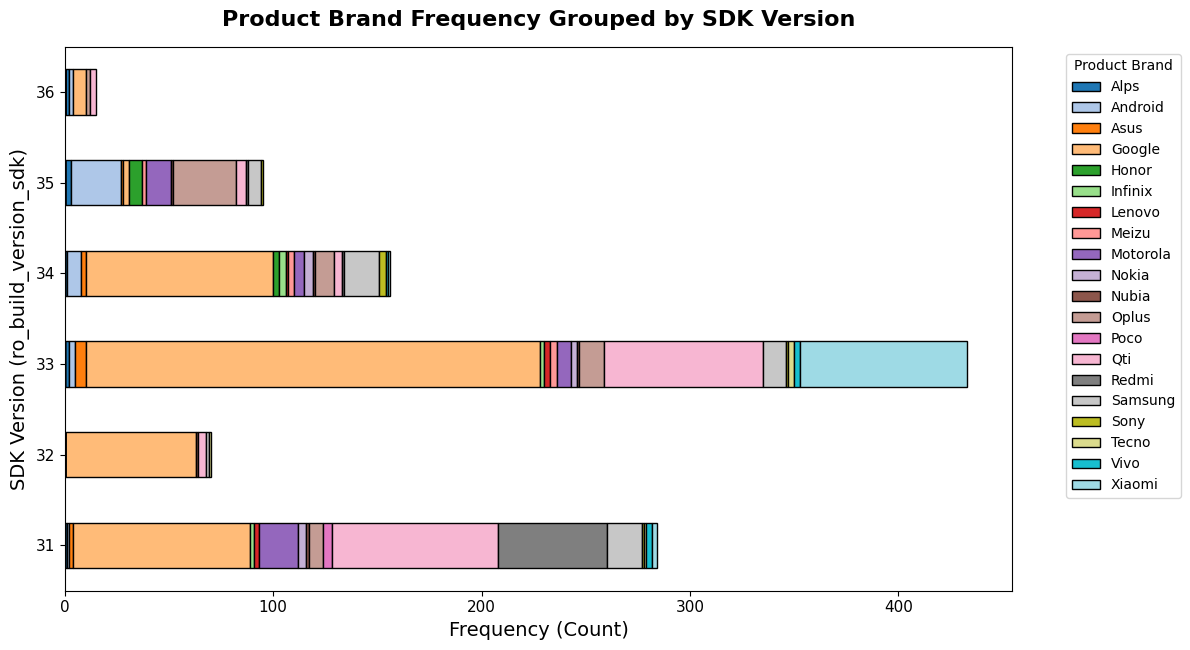

In [195]:
# 1. Process and extract the grouped data frame
df_grouped = get_grouped_brand_by_sdk(data_dict, firmware_id_list)

# 2. Plot the result
plot_grouped_brand_by_sdk(
    df_grouped,
    title="Product Brand Frequency Grouped by SDK Version",
    output_file="./images/Dataset_brand_by_sdk_stacked.pdf",
    top_n_brands=20 # Shows only top 10 brands to prevent legend bloat; change as needed
)